In [1]:
print("ACTIVIDAD FORMATIVA 4")
print("IMPLEMENTACION DE UN SISTEMA DE MODULACION AM")
print("Lenguaje de programacion: Python")

ACTIVIDAD FORMATIVA 4
IMPLEMENTACION DE UN SISTEMA DE MODULACION AM
Lenguaje de programacion: Python


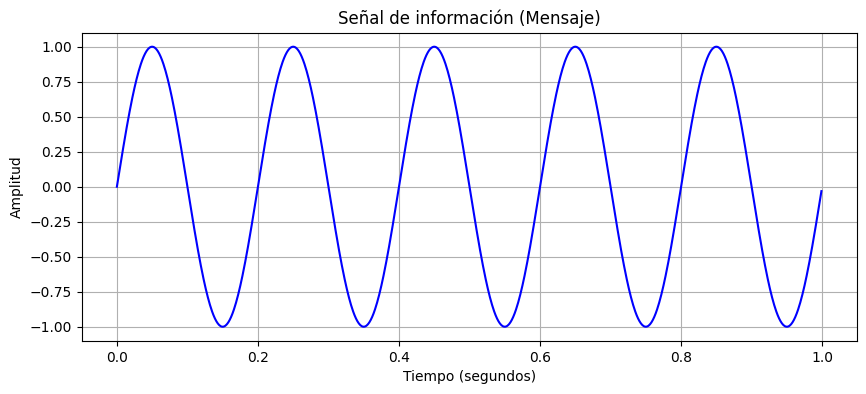

In [2]:

import numpy as np
import matplotlib.pyplot as plt

# Configuracion de la señal
fm = 5                  # Frecuencia del mensaje (Hz)
Am = 1                  # Amplitud del mensaje
fs = 1000               # Frecuencia de muestreo
t = np.arange(0, 1, 1/fs)

# Creacion de la señal de informacion
mensaje = Am * np.sin(2 * np.pi * fm * t)

# Grafica de la señal
plt.figure(figsize=(10, 4))
plt.plot(t, mensaje, color='blue')
plt.title("Señal de información (Mensaje)")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.grid(True)
plt.show()


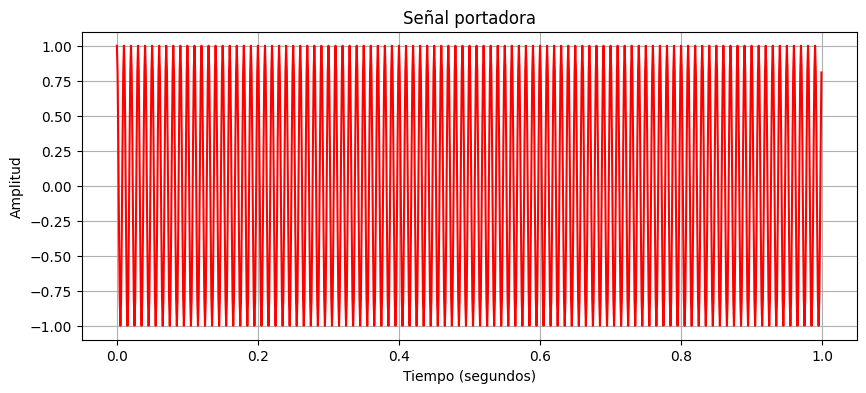

In [3]:

# Creacion de la señal portadora

fc = 100       # Frecuencia de la portadora (Hz)
Ac = 1         # Amplitud de la portadora

# Generar la portadora
portadora = Ac * np.cos(2 * np.pi * fc * t)

# Graficar la portadora
plt.figure(figsize=(10, 4))
plt.plot(t, portadora, color='red')
plt.title("Señal portadora")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.grid(True)
plt.show()

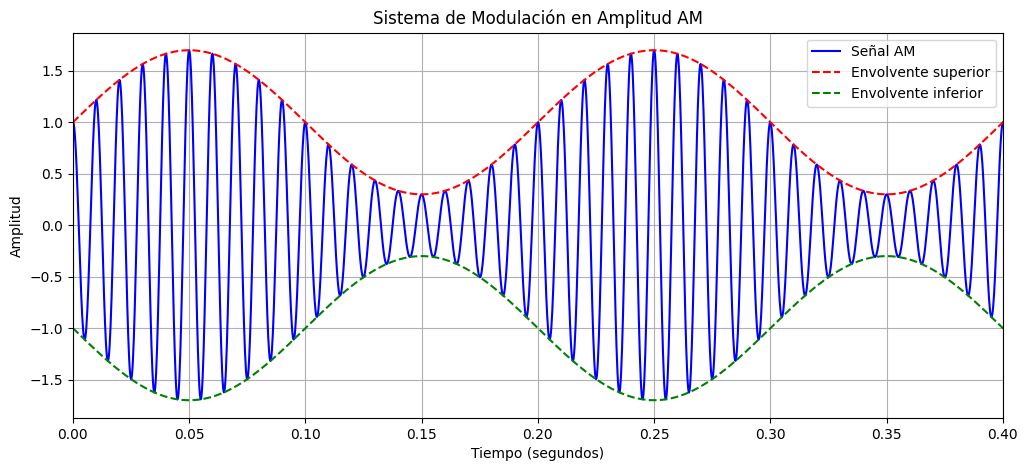

In [4]:

# IMPLEMENTACION DE LA MODULACION AM

# Configuracion
fs = 5000
t = np.arange(0, 1, 1/fs)

fm = 5
fc = 100
Am = 1
Ac = 1
mu = 0.7  # Indice de modulacion

# Generar señal de informacion
mensaje = Am * np.sin(2 * np.pi * fm * t)

# Generar señal portadora
portadora = Ac * np.cos(2 * np.pi * fc * t)

# Generar señal modulada AM
senal_AM = Ac * (1 + mu * mensaje) * np.cos(2 * np.pi * fc * t)

# Graficar la señal modulada
plt.figure(figsize=(12, 5))
plt.plot(t, senal_AM, color='blue', label='Señal AM')
plt.plot(t, Ac * (1 + mu * mensaje),
         color='red', linestyle='--', label='Envolvente superior')
plt.plot(t, -Ac * (1 + mu * mensaje),
         color='green', linestyle='--', label='Envolvente inferior')

plt.xlim(0, 0.4)
plt.title("Sistema de Modulación en Amplitud AM")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid(True)
plt.show()


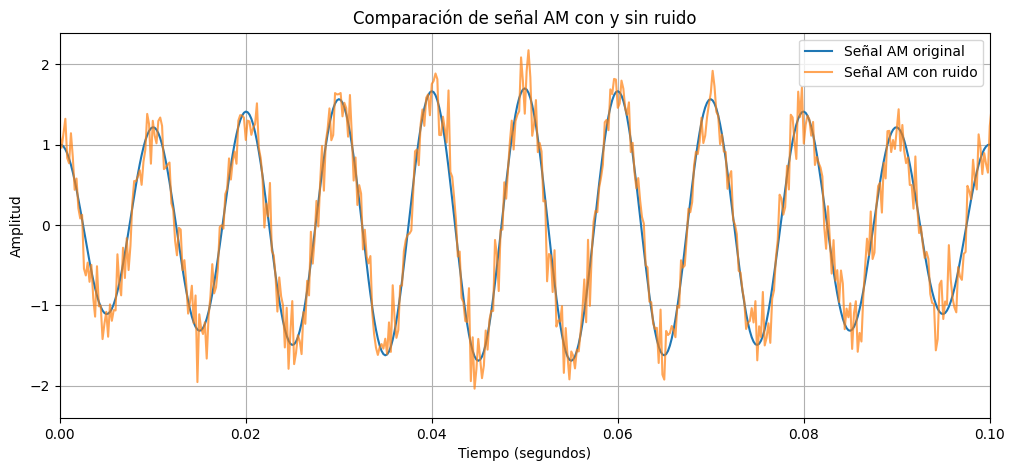

In [6]:

# ANALISIS DEL RUIDO EN LA SEÑAL AM

# Establecer nivel de ruido
np.random.seed(42)
snr_db = 10

# Calcular potencia de la señal
potencia = np.mean(senal_AM**2)

# Calcular potencia del ruido
potencia_ruido = potencia / (10**(snr_db/10))

# Generar ruido aleatorio
ruido = np.random.normal(
    0, np.sqrt(potencia_ruido), len(senal_AM)
)

# Agregar ruido a la señal AM
senal_con_ruido = senal_AM + ruido

# Comparar las señales
plt.figure(figsize=(12, 5))

plt.plot(t, senal_AM, label="Señal AM original")
plt.plot(t, senal_con_ruido,
         label="Señal AM con ruido", alpha=0.7)

plt.xlim(0, 0.1)
plt.title("Comparación de señal AM con y sin ruido")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid(True)
plt.show()


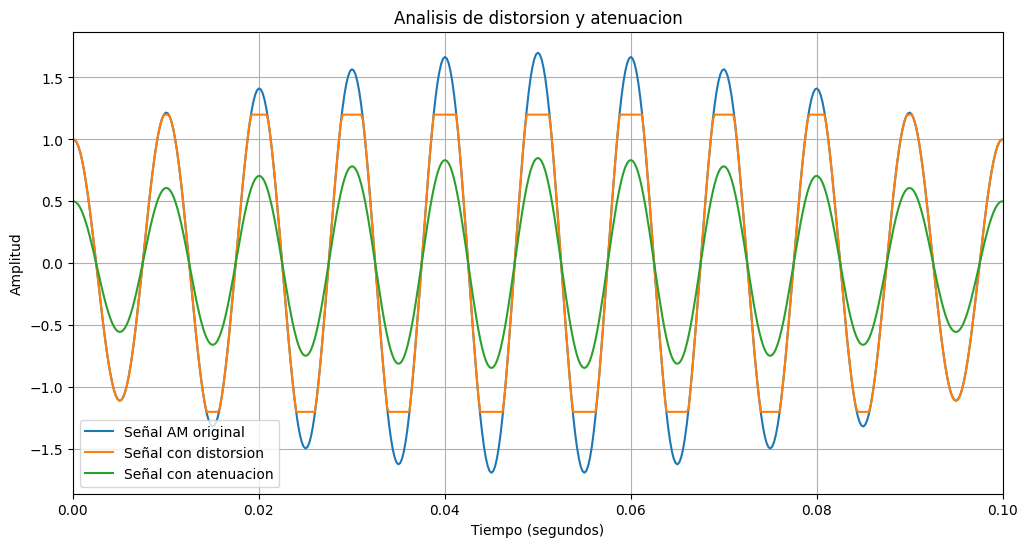

In [7]:

# ANALISIS DE DISTORSION Y ATENUACION

# 1. Generar una señal con distorsion
senal_distorsionada = np.clip(senal_AM, -1.2, 1.2)

# 2. Generar una señal con atenuacion
factor_atenuacion = 0.5
senal_atenuada = senal_AM * factor_atenuacion

# 3. Comparar los resultados
plt.figure(figsize=(12, 6))

plt.plot(t, senal_AM, label="Señal AM original")
plt.plot(t, senal_distorsionada,
         label="Señal con distorsion")
plt.plot(t, senal_atenuada,
         label="Señal con atenuacion")

plt.xlim(0, 0.1)
plt.title("Analisis de distorsion y atenuacion")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid(True)
plt.show()


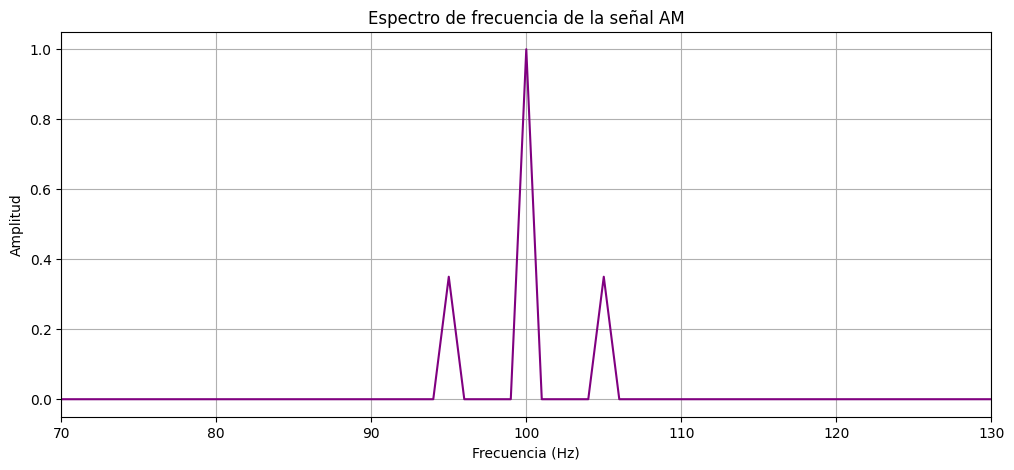

In [8]:

# ANALISIS DE LA MODULACION AM EN EL DOMINIO
# DE LA FRECUENCIA

# Calcular la transformada de Fourier
N = len(senal_AM)
frecuencias = np.fft.fftfreq(N, 1/fs)
espectro = np.fft.fft(senal_AM)

# Obtener frecuencias positivas
frecuencias_positivas = frecuencias[:N//2]
amplitud_espectro = 2 * np.abs(espectro[:N//2]) / N

# Graficar el espectro
plt.figure(figsize=(12, 5))
plt.plot(frecuencias_positivas, amplitud_espectro,
         color='purple')

plt.title("Espectro de frecuencia de la señal AM")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.xlim(70, 130)
plt.grid(True)
plt.show()


### Análisis e interpretación de resultados

Durante la implementación del sistema de modulación en amplitud (AM), se generó una señal de información de 5 Hz y una señal portadora de 100 Hz.

Se obtuvo una señal modulada con un índice de modulación del 70%, observando cómo la amplitud de la portadora cambia de acuerdo con la señal de información.

Posteriormente, se realizaron pruebas para analizar diferentes condiciones de comunicación:

- **Ruido:** se observaron variaciones no deseadas en la señal recibida.
- **Distorsión:** se modificó la forma de onda mediante el recorte de sus amplitudes.
- **Atenuación:** se redujo la amplitud de la señal al 50% de su valor original.
- **Dominio de la frecuencia:** se identificaron tres componentes principales en 95 Hz, 100 Hz y 105 Hz.

Los resultados permiten comprobar el funcionamiento de la modulación AM y observar cómo diferentes condiciones afectan la calidad de la transmisión.